# Framework de metamodelagem explicável para SED

Processo completo do trabalho, do plano amostral à explicação do metamodelo:
DoE → replicação → cockpit do ProModel → leitura dos resultados → pré-processamento →
treinamento do MLP → avaliação → explicabilidade → simulação por metamodelo.

A simulação em si é feita no ProModel, fora deste notebook. Por isso, a partir da leitura
dos resultados, são usados os cockpits já simulados de `promodel_cockpits/` (o maior plano
amostral de cada cenário). Execute o notebook com a pasta `Código/` como diretório de trabalho.

## Imports

Bibliotecas e módulos do framework (pasta `modulos/`).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modulos.config import load_scenario_config, round_design
from modulos.doe.parameter_space import generate_design
from modulos.doe.replication import ReplicationPolicy, build_execution_plan
from modulos.sim_interface.excel_bridge import (STATUS_COL, build_cockpit_table, extract_results,
                                                read_promodel_cockpit, select_complete_runs,
                                                write_promodel_cockpit)
from modulos.preprocessing.pipeline import PreprocessingPipeline, TargetTransformSpec
from modulos.metamodels import CATALOGO
from modulos.evaluation.metrics import regression_metrics
from modulos.evaluation.tuning import tune_grouped
from modulos.evaluation.validation import cross_validate_grouped
from modulos.xai.shap_values import compute_shap, importance_by_parameter
from modulos.xai.surrogate import OriginalScaleSurrogate
from modulos.xai.graficos import grafico_pdp_ice, grafico_shap

## Configuração dos cenários

Carrega e valida os YAMLs dos três cenários.

In [2]:
PASTA_CONFIGS = Path("cenario_configs")
ARQUIVOS_CONFIG = {1: "scenario_01_serial.yaml", 2: "scenario_02_routing.yaml", 3: "scenario_03_multiproduto.yaml"}

configs = {n: load_scenario_config(PASTA_CONFIGS / arq) for n, arq in ARQUIVOS_CONFIG.items()}

for n, cfg in configs.items():
    print(f"Cenário {n} ({cfg.scenario.description}): {len(cfg.factors)} parâmetros de entrada, "
          f"{len(cfg.responses)} saídas no cockpit")

Cenário 1 (Linha de produção serial P1 -> P2 -> P3 (baseline)): 9 parâmetros de entrada, 13 saídas no cockpit
Cenário 2 (Roteamento probabilístico em 3 caminhos, 2 máquinas por processo): 15 parâmetros de entrada, 28 saídas no cockpit
Cenário 3 (Multiproduto: 3 produtos em 3 máquinas compartilhadas com buffers): 9 parâmetros de entrada, 36 saídas no cockpit


## DoE

Uma célula por método de amostragem. Basta executar uma delas: todas gravam o plano em
`plano_amostral`, usado na replicação. Ao executar o notebook inteiro, vale o último (LHS). Os valores float são arredondados às casas declaradas no YAML.

**Monte Carlo**: sorteio uniforme independente, a referência de comparação dos outros métodos.

In [3]:
CENARIO = 3
N_PONTOS = 600
SEMENTE_DOE = 2611103

config = configs[CENARIO]
plano_amostral = round_design(generate_design(config.to_parameter_specs(), n_points=N_PONTOS, seed=SEMENTE_DOE,
                                              method="monte_carlo"), config)
plano_amostral.head()

,Capacidade M1,Quantidade chegada,Ocorrências chegada,Frequência chegada,Tempo processo 1,Capacidade M2,Capacidade M3,Tempo processo 2,Tempo processo 3
0,1,2,130,6.2,6.8,3,3,9.0,7.3
1,2,1,92,13.2,7.2,1,2,8.3,3.9
2,2,1,89,10.5,3.6,2,3,2.2,9.6
3,3,1,64,13.9,5.6,2,1,2.0,8.0
4,1,1,55,8.1,5.3,3,2,7.3,8.0


**Sobol**: sequência de baixa discrepância; o número de pontos deve ser potência de 2.

In [4]:
CENARIO = 3
N_PONTOS = 512
SEMENTE_DOE = 2611103

config = configs[CENARIO]
plano_amostral = round_design(generate_design(config.to_parameter_specs(), n_points=N_PONTOS, seed=SEMENTE_DOE,
                                              method="sobol"), config)
plano_amostral.head()

,Capacidade M1,Quantidade chegada,Ocorrências chegada,Frequência chegada,Tempo processo 1,Capacidade M2,Capacidade M3,Tempo processo 2,Tempo processo 3
0,2,1,148,6.7,4.8,2,3,6.4,3.6
1,3,2,74,15.0,9.4,1,2,2.3,9.8
2,3,1,104,9.4,7.1,1,3,5.9,6.1
3,1,2,80,11.7,2.6,3,1,9.8,4.3
4,1,1,56,10.7,3.3,2,2,4.3,7.9


**LHS** com critério ESE, o método usado nos três cenários.

In [5]:
CENARIO = 3
N_PONTOS = 600
SEMENTE_DOE = 2611103

config = configs[CENARIO]
plano_amostral = round_design(generate_design(config.to_parameter_specs(), n_points=N_PONTOS, seed=SEMENTE_DOE,
                                              method="lhs", criterion="ese"), config)
plano_amostral.head()

,Capacidade M1,Quantidade chegada,Ocorrências chegada,Frequência chegada,Tempo processo 1,Capacidade M2,Capacidade M3,Tempo processo 2,Tempo processo 3
0,3,1,97,11.4,5.9,1,3,8.7,5.6
1,2,2,63,9.4,8.2,1,2,5.8,3.1
2,3,1,148,9.1,3.2,1,2,6.6,8.9
3,3,2,59,12.4,8.7,2,1,6.9,8.1
4,3,1,62,12.7,6.0,3,3,3.6,5.0


## Replicação

Expande cada ponto em `N_REPLICACOES` execuções, identificadas por `point_id`, `replication_id` e `unique_id`.

In [6]:
N_REPLICACOES = 2

plano_execucao = build_execution_plan(plano_amostral, ReplicationPolicy(n_replications=N_REPLICACOES))
print(f"{len(plano_amostral)} pontos x {N_REPLICACOES} replicações = {len(plano_execucao)} execuções")
plano_execucao.head()

600 pontos x 2 replicações = 1200 execuções


,point_id,replication_id,unique_id,Capacidade M1,Quantidade chegada,Ocorrências chegada,Frequência chegada,Tempo processo 1,Capacidade M2,Capacidade M3,Tempo processo 2,Tempo processo 3
0,0,0,0,3,1,97,11.4,5.9,1,3,8.7,5.6
1,0,1,1,3,1,97,11.4,5.9,1,3,8.7,5.6
2,1,0,2,2,2,63,9.4,8.2,1,2,5.8,3.1
3,1,1,3,2,2,63,9.4,8.2,1,2,5.8,3.1
4,2,0,4,3,1,148,9.1,3.2,1,2,6.6,8.9


## Exportação do cockpit

Grava o cockpit Excel lido pela macro do ProModel: entradas, saídas vazias e colunas de identificação.

In [7]:
ARQUIVO_COCKPIT_NOVO = Path("saidas") / f"cockpit_cenario_{CENARIO}_novo.xlsx"

ARQUIVO_COCKPIT_NOVO.parent.mkdir(exist_ok=True)
cockpit = build_cockpit_table(plano_execucao, config.response_names)
write_promodel_cockpit(cockpit, str(ARQUIVO_COCKPIT_NOVO), config.factor_names, config.response_names,
                       sheet_name=config.cockpit.sheet_name, item_column=config.cockpit.item_column,
                       item_prefix=config.cockpit.item_prefix)
print(f"{ARQUIVO_COCKPIT_NOVO}: {len(cockpit)} linhas, {len(config.factor_names)} entradas, "
      f"{len(config.response_names)} saídas vazias")

saidas\cockpit_cenario_3_novo.xlsx: 1200 linhas, 9 entradas, 36 saídas vazias


## Importação dos resultados

Lê o cockpit já simulado no ProModel para o cenário escolhido e mantém as execuções completas,
com entradas e saídas.
O aviso de leitura *best-effort* é esperado: o arquivo salvo pela macro do ProModel não traz a aba de esquema do cockpit gerado.

In [8]:
ARQUIVO_COCKPIT_SIMULADO = next(Path("promodel_cockpits").glob(f"cockpit_cenario_{CENARIO}_*.xlsm"))

todas = extract_results(read_promodel_cockpit(str(ARQUIVO_COCKPIT_SIMULADO), config.cockpit.sheet_name),
                        config.response_names)
dados = select_complete_runs(todas)
print(f"{ARQUIVO_COCKPIT_SIMULADO.name}: {todas[STATUS_COL].value_counts().to_dict()}; "
      f"{dados['point_id'].nunique()} pontos completos")
dados[config.factor_names + config.response_names].head()

Cockpit promodel_cockpits\cockpit_cenario_3_lhs_600x2.xlsm sem a aba '_sed_meta_schema': leitura best-effort. Ver read_promodel_cockpit().


cockpit_cenario_3_lhs_600x2.xlsm: {'completa': 1200}; 600 pontos completos


,Capacidade M1,Quantidade chegada,Ocorrências chegada,Frequência chegada,Tempo processo 1,Capacidade M2,Capacidade M3,Tempo processo 2,Tempo processo 3,Entrada_1,...,Feito_P1_3,Feito_P2_1,Feito_P2_2,Feito_P2_3,Feito_P3_1,Feito_P3_2,Feito_P3_3,Tempo_total_1,Tempo_total_2,Tempo_total_3
0,3,1,97,11.4,5.9,1,3,8.7,5.6,35,...,30,35,32,30,35,32,30,1212.000000,1212.000000,1344.400000
1,3,1,97,11.4,5.9,1,3,8.7,5.6,29,...,38,29,30,38,29,30,38,1212.000000,1212.000000,1317.157895
2,2,2,63,9.4,8.2,1,2,5.8,3.1,42,...,41,42,43,41,42,43,41,5435.428571,5018.093023,5477.414634
3,2,2,63,9.4,8.2,1,2,5.8,3.1,38,...,47,38,41,47,38,41,47,5090.210526,5860.975610,5906.936170
4,3,1,148,9.1,3.2,1,2,6.6,8.9,51,...,44,51,53,44,51,53,44,1194.000000,1125.283019,1314.272727


## Pré-processamento

Divide treino e teste por ponto (todas as réplicas de um ponto ficam do mesmo lado), escala as entradas
para [0, 1] pelos limites do YAML e padroniza os indicadores com estatísticas só do treino.

In [9]:
TEST_SIZE = 0.2
SEMENTE = 0

targets = config.response_names
pipe = PreprocessingPipeline(config.to_parameter_specs(), [TargetTransformSpec(k, "standard") for k in targets])
train_df, test_df = pipe.split(dados, test_size=TEST_SIZE, seed=SEMENTE)
pipe.fit(train_df)
X_train, X_test = pipe.transform_X(train_df), pipe.transform_X(test_df)

print(f"Treino: {train_df['point_id'].nunique()} pontos ({len(train_df)} linhas); "
      f"teste: {test_df['point_id'].nunique()} pontos ({len(test_df)} linhas)")
print("Targets possíveis:", targets)

Treino: 480 pontos (960 linhas); teste: 120 pontos (240 linhas)
Targets possíveis: ['Entrada_1', 'Entrada_2', 'Entrada_3', 'Prontas_1', 'Prontas_2', 'Prontas_3', 'Tempo_ate_P1_1', 'Tempo_ate_P1_2', 'Tempo_ate_P1_3', 'Tempo_ate_P2_1', 'Tempo_ate_P2_2', 'Tempo_ate_P2_3', 'Tempo_ate_P3_1', 'Tempo_ate_P3_2', 'Tempo_ate_P3_3', 'Tempo_P1_1', 'Tempo_P1_2', 'Tempo_P1_3', 'Tempo_P2_1', 'Tempo_P2_2', 'Tempo_P2_3', 'Tempo_P3_1', 'Tempo_P3_2', 'Tempo_P3_3', 'Feito_P1_1', 'Feito_P1_2', 'Feito_P1_3', 'Feito_P2_1', 'Feito_P2_2', 'Feito_P2_3', 'Feito_P3_1', 'Feito_P3_2', 'Feito_P3_3', 'Tempo_total_1', 'Tempo_total_2', 'Tempo_total_3']


## Treinamento do metamodelo

Busca de hiperparâmetros do MLP por validação cruzada agrupada por ponto, sorteando `N_ITER` combinações da grade da família. Trocando `MODELO` por outra chave de `CATALOGO` (`random_forest`, `xgboost`, `gp`, `poly_ridge`...), a mesma célula busca os hiperparâmetros de outra família.

In [10]:
MODELO = "mlp"
TARGET = "Tempo_ate_P2_3"
N_ITER = 20
N_PARTICOES = 5

construtor, grade = CATALOGO[MODELO]
y_train, y_test = pipe.transform_y(train_df, TARGET), pipe.transform_y(test_df, TARGET)
busca = tune_grouped(construtor(), grade, X_train, y_train, train_df["point_id"],
                     n_splits=N_PARTICOES, n_iter=N_ITER, seed=SEMENTE, n_jobs=-1)
print(f"{busca['n_candidatos']} combinações em {busca['tempo_s']:.0f} s; melhor: {busca['params']} "
      f"(R² médio de validação, escala padronizada: {busca['cv_score']:.3f})")
print("Opções de MODELO:", list(CATALOGO))

20 combinações em 19 s; melhor: {'hidden_layer_sizes': (32, 32), 'alpha': 0.01, 'activation': 'tanh'} (R² médio de validação, escala padronizada: 0.955)
Opções de MODELO: ['dummy', 'poly_ridge', 'random_forest', 'extra_trees', 'gradient_boosting', 'xgboost', 'gp', 'mlp']


Treina o metamodelo com `HIPERPARAMETROS`. Os valores abaixo são os escolhidos na busca da monografia para `Tempo_ate_P2_3`; para usar o resultado da célula anterior, troque por `busca["params"]`.

In [11]:
HIPERPARAMETROS = {"hidden_layer_sizes": (32, 32), "alpha": 1.0, "activation": "relu"}

modelo = construtor().set_params(**HIPERPARAMETROS)
t0 = time.perf_counter()
modelo.fit(X_train, y_train)
print(f"{MODELO} {HIPERPARAMETROS} treinado em {time.perf_counter() - t0:.1f} s")

mlp {'hidden_layer_sizes': (32, 32), 'alpha': 1.0, 'activation': 'relu'} treinado em 0.7 s


## Avaliação

R², MAE e RMSE em segundos: média das partições de validação cruzada agrupada por ponto (a medida das
tabelas da monografia) e conjunto de teste.

In [12]:
inversa = lambda y: pipe.inverse_transform_y(y, TARGET)
cv = cross_validate_grouped(construtor().set_params(**HIPERPARAMETROS), X_train, y_train, train_df["point_id"],
                            n_splits=N_PARTICOES, inverse=inversa)
validacao = cv[cv["conjunto"] == "validacao"][["r2", "mae", "rmse"]].mean()
teste = pd.Series(regression_metrics(inversa(y_test), inversa(modelo.predict(X_test))))[["r2", "mae", "rmse"]]
pd.DataFrame({"validação cruzada (média)": validacao, "teste": teste}).rename(
    index={"r2": "R²", "mae": "MAE (s)", "rmse": "RMSE (s)"}).round(3)

,validação cruzada (média),teste
R²,0.936,0.985
MAE (s),444.716,297.436
RMSE (s),1233.609,809.761


## Explicabilidade (XAI)

SHAP nos pontos de teste e PDP com curvas ICE dos três parâmetros mais importantes, no formato das
figuras da monografia.

,parametro,fracao
0,Capacidade M2,0.304
1,Tempo processo 2,0.228
2,Quantidade chegada,0.199
3,Frequência chegada,0.161
4,Ocorrências chegada,0.063
5,Capacidade M1,0.013


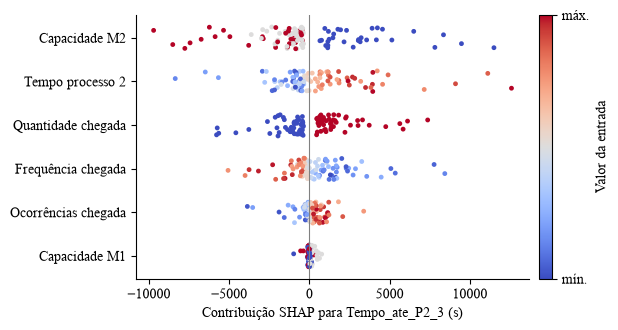

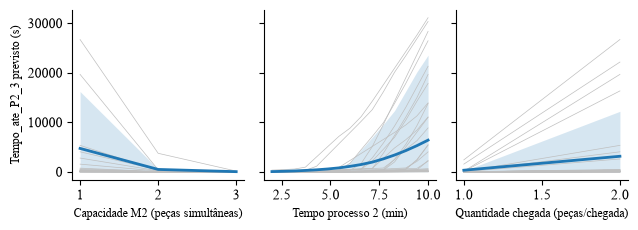

In [13]:
N_PONTOS_SHAP = 100
N_PARAMETROS_GRAFICO = 6

specs = {s.name: s for s in config.to_parameter_specs()}
pontos = test_df.drop_duplicates("point_id")
pontos = pontos.sample(min(N_PONTOS_SHAP, len(pontos)), random_state=SEMENTE)
shap_res = compute_shap(modelo, pipe.transform_X(pontos), pipe.get_feature_names(),
                        X_background=X_train, seed=SEMENTE, n_background=50)
shap_s = shap_res.values.apply(lambda c: inversa(c.to_numpy()) - inversa(np.zeros(len(c))))  # em segundos
importancia = importance_by_parameter(shap_res, list(specs.values()))
top = list(importancia["parametro"].head(N_PARAMETROS_GRAFICO))
display(importancia[["parametro", "fracao"]].head(N_PARAMETROS_GRAFICO).round(3))

grafico_shap(shap_s, pontos, specs, TARGET, top)
plt.show()
surrogate = OriginalScaleSurrogate(modelo, pipe, TARGET)
grafico_pdp_ice(surrogate, train_df, specs, TARGET, top[:3], {f.name: f.unit for f in config.factors})
plt.show()

## Simulação por metamodelo

Prevê `N_PREVISOES` combinações de parâmetros sorteadas por LHS no espaço do cenário e compara o tempo
com o de simulá-las no ProModel.

In [14]:
N_PREVISOES = 100_000
TEMPO_MEDIO_EXECUCAO_S = {1: 3.54, 2: 2.71, 3: 3.29}   # média por execução no ProModel (Tabela 9 da monografia)

t0 = time.perf_counter()
novos_pontos = generate_design(config.to_parameter_specs(), N_PREVISOES, seed=123, method="lhs", criterion="center")
t_plano = time.perf_counter() - t0
t0 = time.perf_counter()
previsoes = surrogate(novos_pontos)
t_previsao = time.perf_counter() - t0

print(f"Plano de {N_PREVISOES:,} pontos gerado em {t_plano:.1f} s".replace(",", "."))
print(f"Previsão de {TARGET} em {t_previsao:.2f} s")
print(f"Simulação equivalente no ProModel: {N_PREVISOES * TEMPO_MEDIO_EXECUCAO_S[CENARIO] / 3600:.0f} h")

Plano de 100.000 pontos gerado em 0.0 s
Previsão de Tempo_ate_P2_3 em 0.04 s
Simulação equivalente no ProModel: 91 h
